In [4]:
from pathlib import Path

data_dir = Path("Data/PBC_dataset_normal_DIB")

def real_images(folder):
    return [p for p in folder.glob("*.jpg") if not p.name.startswith(".")]

counts = {f.name: len(real_images(f)) for f in sorted(data_dir.iterdir()) if f.is_dir()}
print(counts)
print("Total:", sum(counts.values()))

{'basophil': 1218, 'eosinophil': 3117, 'erythroblast': 1551, 'ig': 2895, 'lymphocyte': 1214, 'monocyte': 1420, 'neutrophil': 3329, 'platelet': 2348}
Total: 17092


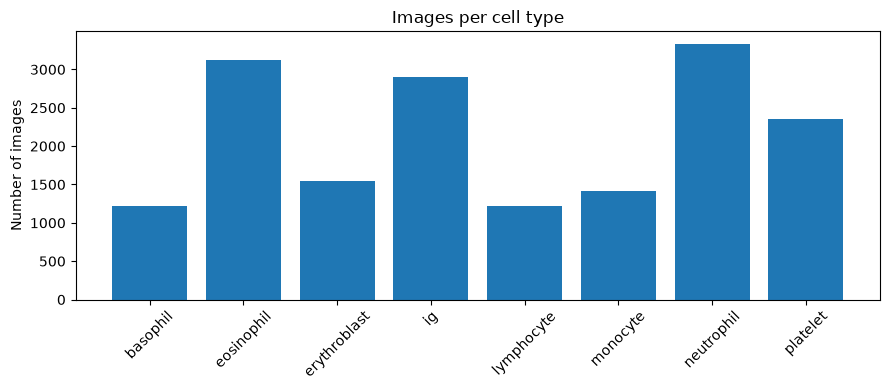

In [2]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 4))
plt.bar(counts.keys(), counts.values())
plt.xticks(rotation=45)
plt.ylabel("Number of images")
plt.title("Images per cell type")
plt.tight_layout()
plt.show()

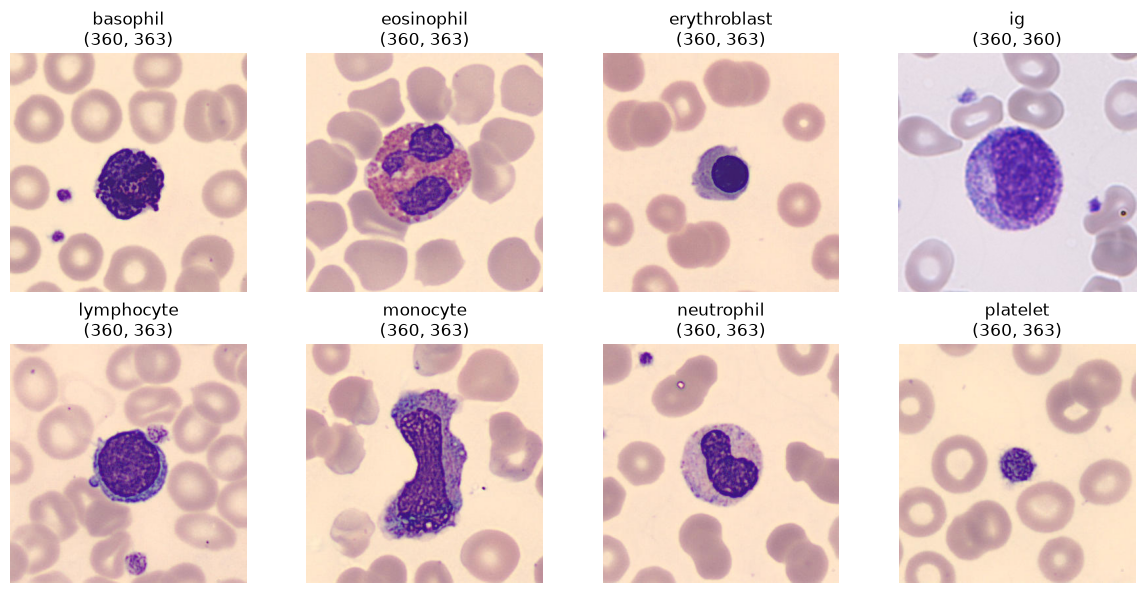

In [5]:
from PIL import Image
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, cls in zip(axes.flat, counts):
    img_path = real_images(data_dir / cls)[0]
    img = Image.open(img_path)
    ax.imshow(img)
    ax.set_title(f"{cls}\n{img.size}")
    ax.axis("off")
plt.tight_layout()
plt.show()

## Day 3 observations
- 17,092 images, 8 classes. Neutrophils are the largest class (3,329) and lymphocytes the smallest (1,214), about a 2.7x gap.
- Basophils and lymphocytes are both under 1,300 images, so the model may struggle with them.
- Sizes are mostly 360x363, but at least one image is 360x360, so I'll resize everything on Day 4.
- Likely hard pairs: neutrophil vs. immature granulocyte, and monocyte vs. lymphocyte.
- The Mac zip left hidden junk files (.DS_ files). I filter out filenames that start with a dot.

